# Deep Plain CNN — Malaria Cell Classification
**Model:** Custom Deep Plain CNN
**Dataset:** NIH Malaria Cell Images (Parasitized vs Uninfected)

## Part 1 — Project & Environment Setup

In [4]:
# 1. Imports
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (
    confusion_matrix, classification_report,
    roc_curve, auc, precision_score, recall_score, f1_score
)

In [5]:
# 2. Random seeds
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [6]:
# 3. Configuration
IMG_SIZE    = (128, 128)
BATCH_SIZE  = 32
EPOCHS      = 10
LR          = 1e-3
DROPOUT     = 0.5
NUM_CLASSES = 1          # binary → sigmoid output

# 4. Paths
BASE_DIR      = os.path.abspath(os.path.join(os.getcwd(), '..'))
DATA_DIR      = os.path.join(BASE_DIR, 'data', 'cell_images')
MODELS_DIR    = os.path.join(BASE_DIR, 'models')
LOGS_DIR      = os.path.join(BASE_DIR, 'logs', 'fit')
FIGURES_DIR   = os.path.join(BASE_DIR, 'outputs', 'figures')
CM_DIR        = os.path.join(BASE_DIR, 'outputs', 'confusion_matrix')
ROC_DIR       = os.path.join(BASE_DIR, 'outputs', 'roc')
GRADCAM_DIR   = os.path.join(BASE_DIR, 'outputs', 'gradcam')

PARASITIZED_DIR = os.path.join(DATA_DIR, 'Parasitized')
UNINFECTED_DIR  = os.path.join(DATA_DIR, 'Uninfected')

In [7]:
# 5. Check TensorFlow / GPU
print('TensorFlow version:', tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print('GPUs available:', gpus if gpus else 'None — using CPU')

TensorFlow version: 2.20.0
GPUs available: None — using CPU


## Part 2 — Dataset

In [8]:
# 6. Locate dataset
print('Data directory:', DATA_DIR)
print('Exists:', os.path.exists(DATA_DIR))

Data directory: c:\Users\user\Documents\malaria-cnn\data\cell_images
Exists: True


In [9]:
# 7. Check folder structure
for folder in [PARASITIZED_DIR, UNINFECTED_DIR]:
    print(folder, '→ exists:', os.path.exists(folder))

c:\Users\user\Documents\malaria-cnn\data\cell_images\Parasitized → exists: True
c:\Users\user\Documents\malaria-cnn\data\cell_images\Uninfected → exists: True


In [10]:
# 8. Count images
def count_images(path):
    return len([f for f in os.listdir(path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])

n_parasitized = count_images(PARASITIZED_DIR)
n_uninfected  = count_images(UNINFECTED_DIR)
print(f'Parasitized (infected):  {n_parasitized}')
print(f'Uninfected:              {n_uninfected}')
print(f'Total:                   {n_parasitized + n_uninfected}')

Parasitized (infected):  13779
Uninfected:              13779
Total:                   27558


## Part 3 — Data Preparation

In [11]:
# 9. Define image size & 12. Define batch size (already in config)
print(f'Image size:  {IMG_SIZE}')
print(f'Batch size:  {BATCH_SIZE}')

Image size:  (128, 128)
Batch size:  32


In [12]:
# 10. Create train / validation / test datasets
# 80% train | 10% val | 10% test  (fixed seed for reproducibility)
AUTOTUNE = tf.data.AUTOTUNE

full_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    labels='inferred',
    label_mode='binary',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

class_names = full_ds.class_names
print('Classes:', class_names)

total_batches = tf.data.experimental.cardinality(full_ds).numpy()
train_size = int(0.8 * total_batches)
val_size   = int(0.1 * total_batches)

train_ds = full_ds.take(train_size)
val_ds   = full_ds.skip(train_size).take(val_size)
test_ds  = full_ds.skip(train_size + val_size)

print(f'Train batches: {tf.data.experimental.cardinality(train_ds).numpy()}')
print(f'Val   batches: {tf.data.experimental.cardinality(val_ds).numpy()}')
print(f'Test  batches: {tf.data.experimental.cardinality(test_ds).numpy()}')

Found 27558 files belonging to 2 classes.
Classes: ['Parasitized', 'Uninfected']
Train batches: 689
Val   batches: 86
Test  batches: 87


In [13]:
# 11. Normalise images (rescale [0,255] → [0,1])
normalise = layers.Rescaling(1./255)

train_ds = train_ds.map(lambda x, y: (normalise(x), y), num_parallel_calls=AUTOTUNE)
val_ds   = val_ds.map(lambda x, y: (normalise(x), y),   num_parallel_calls=AUTOTUNE)
test_ds  = test_ds.map(lambda x, y: (normalise(x), y),  num_parallel_calls=AUTOTUNE)

In [14]:
# 12. Data augmentation (applied only to training set)
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name='data_augmentation')

train_ds = train_ds.map(lambda x, y: (data_augmentation(x, training=True), y),
                        num_parallel_calls=AUTOTUNE)

# Cache & prefetch for performance
train_ds = train_ds.cache().prefetch(AUTOTUNE)
val_ds   = val_ds.cache().prefetch(AUTOTUNE)
test_ds  = test_ds.cache().prefetch(AUTOTUNE)

print('Data pipeline ready.')

Data pipeline ready.


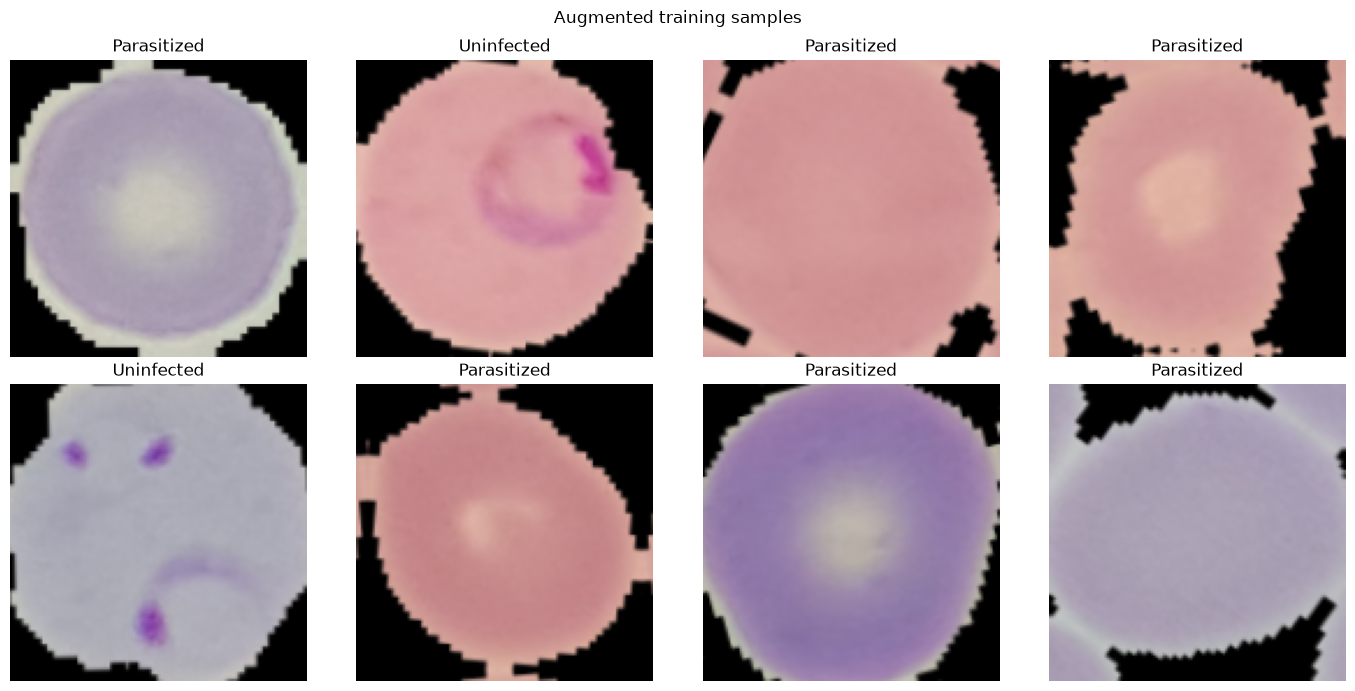

In [15]:
# Quick sanity check — show one augmented batch
for images, labels in train_ds.take(1):
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for i, ax in enumerate(axes.flat):
        ax.imshow(images[i].numpy())
        ax.set_title('Parasitized' if labels[i] == 1 else 'Uninfected')
        ax.axis('off')
    plt.suptitle('Augmented training samples')
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_DIR, 'augmented_samples.png'), dpi=150)
    plt.show()

In [16]:
# Verify class mapping
print('Class indices → 0:', class_names[0], '| 1:', class_names[1])
print('Parasitized = infected → label 1' if class_names[1] == 'Parasitized' else 'Parasitized = infected → label 0')

Class indices → 0: Parasitized | 1: Uninfected
Parasitized = infected → label 0


In [17]:
# Keep an unbatched test set for per-image evaluation later
test_ds_unbatched = test_ds.unbatch()

In [18]:
# Collect all test labels and images for sklearn metrics
y_test_true = np.concatenate([y.numpy() for _, y in test_ds], axis=0).flatten()
print(f'Test samples: {len(y_test_true)}')
print(f'Parasitized in test: {y_test_true.sum():.0f} | Uninfected: {(1-y_test_true).sum():.0f}')

Test samples: 2758
Parasitized in test: 1376 | Uninfected: 1382


In [19]:
# Save test images array for Grad-CAM later
X_test = np.concatenate([x.numpy() for x, _ in test_ds], axis=0)
print(f'X_test shape: {X_test.shape}')

X_test shape: (2758, 128, 128, 3)


In [20]:
# Summary
print('=== Data Preparation Summary ===')
print(f'Image size      : {IMG_SIZE}')
print(f'Batch size      : {BATCH_SIZE}')
print(f'Normalisation   : [0,1]')
print(f'Augmentation    : RandomFlip, RandomRotation(0.1), RandomZoom(0.1)')
print(f'Train batches   : {tf.data.experimental.cardinality(train_ds).numpy()}')
print(f'Val   batches   : {tf.data.experimental.cardinality(val_ds).numpy()}')
print(f'Test  batches   : {tf.data.experimental.cardinality(test_ds).numpy()}')

=== Data Preparation Summary ===
Image size      : (128, 128)
Batch size      : 32
Normalisation   : [0,1]
Augmentation    : RandomFlip, RandomRotation(0.1), RandomZoom(0.1)
Train batches   : 689
Val   batches   : 86
Test  batches   : 87


In [18]:
# ← Part 4 (CNN architecture) will be added next

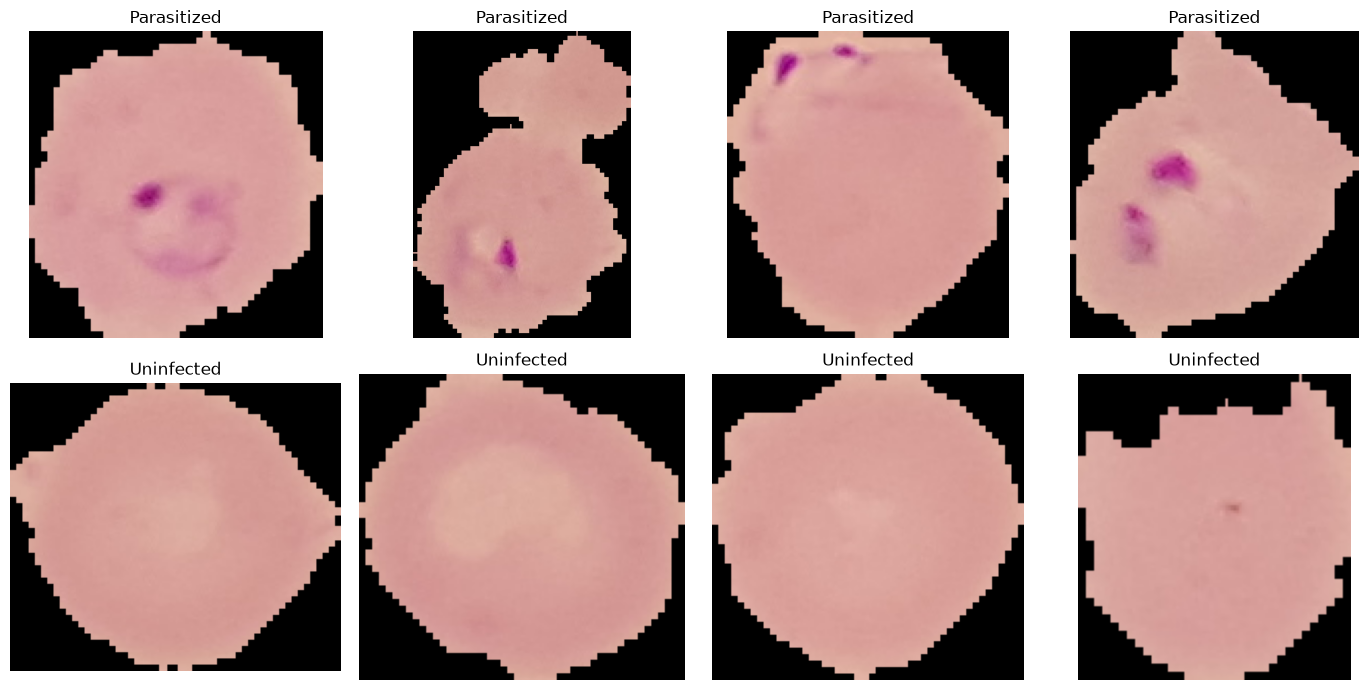

In [21]:
# 9. Visualize sample images
def load_sample_images(folder, n=4):
    files = [f for f in os.listdir(folder) if f.lower().endswith(('.png', '.jpg', '.jpeg'))][:n]
    return [cv2.cvtColor(cv2.imread(os.path.join(folder, f)), cv2.COLOR_BGR2RGB) for f in files]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for i, img in enumerate(load_sample_images(PARASITIZED_DIR, 4)):
    axes[0, i].imshow(img); axes[0, i].set_title('Parasitized'); axes[0, i].axis('off')
for i, img in enumerate(load_sample_images(UNINFECTED_DIR, 4)):
    axes[1, i].imshow(img); axes[1, i].set_title('Uninfected'); axes[1, i].axis('off')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'sample_images.png'), dpi=150)
plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_15016\1372925584.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=labels, y=counts, palette=['tomato', 'steelblue'])


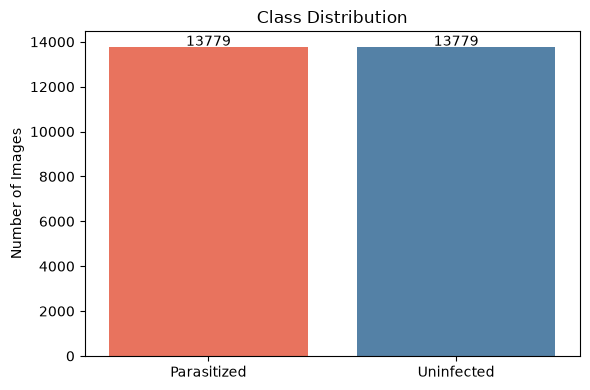

In [22]:
# 10. Check class distribution
labels = ['Parasitized', 'Uninfected']
counts = [n_parasitized, n_uninfected]

plt.figure(figsize=(6, 4))
sns.barplot(x=labels, y=counts, palette=['tomato', 'steelblue'])
plt.title('Class Distribution')
plt.ylabel('Number of Images')
for i, v in enumerate(counts):
    plt.text(i, v + 50, str(v), ha='center')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'class_distribution.png'), dpi=150)
plt.show()

## Part 4 — Model Architecture

In [23]:
# 16. Build Deep Plain CNN
def build_model(input_shape=(128, 128, 3)):
    inputs = keras.Input(shape=input_shape)

    # Block 1
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.25)(x)

    # Block 2
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.25)(x)

    # Block 3
    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.25)(x)

    # Block 4
    x = layers.Conv2D(256, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(256, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.25)(x)

    # Classifier head
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(DROPOUT)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="sigmoid")(x)

    return keras.Model(inputs, outputs, name="deep_plain_cnn")

model = build_model()
model.summary()

Model: "deep_plain_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,242,145 (4.74 MB)

 Trainable params: 1,240,225 (4.73 MB)

 Non-trainable params: 1,920 (7.50 KB)

## Part 5 — Training

In [24]:
# 17. Compile
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LR),
    loss="binary_crossentropy",
    metrics=["accuracy",
             keras.metrics.AUC(name="auc"),
             keras.metrics.Precision(name="precision"),
             keras.metrics.Recall(name="recall")]
)

In [25]:
# 18. Callbacks
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(LOGS_DIR,   exist_ok=True)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(MODELS_DIR, "best_model.keras"),
        monitor="val_auc", mode="max",
        save_best_only=True, verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_auc", mode="max",
        patience=7, restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5,
        patience=3, min_lr=1e-6, verbose=1
    ),
    keras.callbacks.TensorBoard(log_dir=LOGS_DIR, histogram_freq=1)
]

In [ ]:
# 19. Train
history = model.fit(
    train_ds,
    epochs=EPOCHS,
    validation_data=val_ds,
    callbacks=callbacks
)
print("Training complete.")

c:\Users\user\Documents\malaria-cnn\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9212 - auc: 0.9675 - loss: 0.2188 - precision: 0.9056 - recall: 0.9398
Epoch 1: val_auc improved from None to 0.97808, saving model to c:\Users\user\Documents\malaria-cnn\models\best_model.keras

Epoch 1: finished saving model to c:\Users\user\Documents\malaria-cnn\models\best_model.keras
689/689 ━━━━━━━━━━━━━━━━━━━━ 1901s 3s/step - accuracy: 0.9212 - auc: 0.9675 - loss: 0.2188 - precision: 0.9056 - recall: 0.9398 - val_accuracy: 0.9128 - val_auc: 0.9781 - val_loss: 0.2605 - val_precision: 0.8607 - val_recall: 0.9901 - learning_rate: 0.0010
Epoch 2/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9494 - auc: 0.9803 - loss: 0.1586 - precision: 0.9375 - recall: 0.9626
Epoch 2: val_auc improved from 0.97808 to 0.98318, saving model to c:\Users\user\Documents\malaria-cnn\models\best_model.keras

Epoch 2: finished saving model to c:\Users\user\Documents\malaria-cnn\models\best_model.keras
689/689 ━━━━━━━━━━━━━━━━━━━━ 1

## Part 6 — Evaluation

In [1]:
# 20. Evaluate on test set
results = model.evaluate(test_ds, verbose=1)
metric_names = model.metrics_names
for name, val in zip(metric_names, results):
    print(f"{name}: {val:.4f}")

NameError: name 'model' is not defined

In [ ]:
# 21. Collect predictions
y_true, y_pred_prob = [], []
for images, labels in test_ds:
    probs = model.predict(images, verbose=0)
    y_pred_prob.extend(probs.flatten().tolist())
    y_true.extend(labels.numpy().flatten().tolist())

y_true      = np.array(y_true)
y_pred_prob = np.array(y_pred_prob)
y_pred      = (y_pred_prob >= 0.5).astype(int)

In [ ]:
# 22. Classification report
print(classification_report(y_true, y_pred,
                             target_names=class_names))

In [ ]:
# 23. Confusion matrix
os.makedirs(CM_DIR, exist_ok=True)
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title("Confusion Matrix")
plt.tight_layout()
plt.savefig(os.path.join(CM_DIR, "confusion_matrix.png"), dpi=150)
plt.show()

In [ ]:
# 24. ROC curve
os.makedirs(ROC_DIR, exist_ok=True)
fpr, tpr, _ = roc_curve(y_true, y_pred_prob)
roc_auc = auc(fpr, tpr)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}")
ax.plot([0, 1], [0, 1], "k--")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(ROC_DIR, "roc_curve.png"), dpi=150)
plt.show()

## Part 7 — Visualization & Grad-CAM

In [ ]:
# 25. Training curves
os.makedirs(FIGURES_DIR, exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history["loss"],     label="Train Loss")
axes[0].plot(history.history["val_loss"], label="Val Loss")
axes[0].set_title("Loss"); axes[0].legend()

axes[1].plot(history.history["accuracy"],     label="Train Acc")
axes[1].plot(history.history["val_accuracy"], label="Val Acc")
axes[1].set_title("Accuracy"); axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "training_curves.png"), dpi=150)
plt.show()

In [ ]:
# 26. Sample predictions grid
sample_images, sample_labels = next(iter(test_ds))
sample_preds = model.predict(sample_images, verbose=0).flatten()

fig, axes = plt.subplots(3, 5, figsize=(15, 9))
for i, ax in enumerate(axes.flat):
    img = sample_images[i].numpy()
    true_lbl = class_names[int(sample_labels[i])]
    pred_lbl = class_names[int(sample_preds[i] >= 0.5)]
    conf     = sample_preds[i] if sample_preds[i] >= 0.5 else 1 - sample_preds[i]
    color    = "green" if true_lbl == pred_lbl else "red"
    ax.imshow(img)
    ax.set_title(f"T:{true_lbl}\nP:{pred_lbl} ({conf:.2f})",
                 color=color, fontsize=8)
    ax.axis("off")
plt.suptitle("Sample Predictions (green=correct, red=wrong)", y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "sample_predictions.png"),
            dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# 27. Grad-CAM helpers
import tensorflow as tf

def make_gradcam_heatmap(img_array, model, last_conv_layer_name):
    """Return a Grad-CAM heatmap for a single pre-processed image (1,H,W,C)."""
    grad_model = tf.keras.Model(
        inputs=model.inputs,
        outputs=[model.get_layer(last_conv_layer_name).output,
                 model.output]
    )
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        loss = predictions[:, 0]
    grads = tape.gradient(loss, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()


def overlay_gradcam(img_np, heatmap, alpha=0.4):
    """Overlay a Grad-CAM heatmap on a [0,1] RGB image."""
    heatmap_resized = cv2.resize(heatmap, (img_np.shape[1], img_np.shape[0]))
    heatmap_uint8   = np.uint8(255 * heatmap_resized)
    heatmap_color   = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)
    heatmap_color   = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB) / 255.0
    return np.clip(alpha * heatmap_color + (1 - alpha) * img_np, 0, 1)


# Identify the last Conv2D layer name
last_conv = [l.name for l in model.layers if isinstance(l, layers.Conv2D)][-1]
print("Last Conv2D layer:", last_conv)

In [ ]:
# 28. Grad-CAM visualisation (first 6 test images)
os.makedirs(GRADCAM_DIR, exist_ok=True)

sample_images, sample_labels = next(iter(test_ds))
n_show = 6
fig, axes = plt.subplots(n_show, 3, figsize=(12, 4 * n_show))

for i in range(n_show):
    img_np    = sample_images[i].numpy()          # (H,W,3) in [0,1]
    img_batch = np.expand_dims(img_np, 0)          # (1,H,W,3)
    heatmap   = make_gradcam_heatmap(img_batch, model, last_conv)
    overlay   = overlay_gradcam(img_np, heatmap)

    true_lbl  = class_names[int(sample_labels[i])]
    pred_prob = model.predict(img_batch, verbose=0)[0, 0]
    pred_lbl  = class_names[int(pred_prob >= 0.5)]

    axes[i, 0].imshow(img_np);    axes[i, 0].set_title("Original");  axes[i, 0].axis("off")
    axes[i, 1].imshow(heatmap, cmap="jet"); axes[i, 1].set_title("Heatmap"); axes[i, 1].axis("off")
    axes[i, 2].imshow(overlay);  axes[i, 2].set_title(f"T:{true_lbl} P:{pred_lbl}"); axes[i, 2].axis("off")

plt.suptitle("Grad-CAM Visualisations", fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(GRADCAM_DIR, "gradcam_samples.png"),
            dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# 29. Save final model
model.save(os.path.join(MODELS_DIR, "deep_plain_cnn_final.keras"))
print("Model saved to:", os.path.join(MODELS_DIR, "deep_plain_cnn_final.keras"))